# SIDD real-noise denoising: results report

Renders every table and figure from `results/*.json`, `results/*_per_block.npz` and `runs/*/log.csv`; **no model is run here**.
Regenerate the inputs with `bash scripts/run_all.sh` (see the README).

**Test set:** the 1280 official SIDD sRGB validation blocks (40 images × 32 blocks of 256×256), used only for final scoring.
**Protocol:** outputs are clamped and quantized to uint8 before scoring. PSNR is computed in RGB per block and averaged. SSIM follows the SIDD/MATLAB 3-D convention; SSIM-2D is per-channel. LPIPS uses AlexNet. CIs are bootstrapped over the 40 images.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)
from IPython.display import Markdown, display
from sidd_denoise import report
res = report.load_results("results")
rows = report.results_table(res)
display(Markdown(report.markdown_table(rows)))
print("† trained by the NAFNet authors on SIDD-Medium, a superset of our SIDD-Small training data: an upper bound, not a competitor.")

| Method | PSNR ↑ (95% CI) | SSIM ↑ | SSIM-2D ↑ | LPIPS ↓ | DISTS ↓ | Params (trainable) | GMACs | Train h |
|---|---|---|---|---|---|---|---|---|
| Noisy input | 23.66 (22.29–24.99) | 0.4848 | 0.3335 | 0.7918 | – | – | – | – |
| Gaussian filter (σ tuned) | 33.10 (31.72–34.49) | 0.8814 | 0.8512 | 0.4390 | – | – | – | – |
| CBM3D (σ estimated) | 24.89 (23.50–26.24) | 0.5429 | 0.3925 | 0.7443 | – | – | – | – |
| CBM3D (σ tuned) | 34.07 (32.42–35.68) | 0.8957 | 0.8478 | 0.3316 | – | – | – | – |
| DRUNet zero-shot (AWGN prior) | 33.98 (32.13–35.74) | 0.8825 | 0.8328 | 0.3249 | 0.3040 | 32.6M | 138.8 | – |
| SCUNet-real zero-shot | 35.11 (33.48–36.68) | 0.8949 | 0.8687 | 0.2642 | 0.2687 | 17.9M | 74.9 | – |
| SCUNet-real-GAN zero-shot | 34.83 (33.26–36.37) | 0.9048 | 0.8795 | 0.2274 | 0.2343 | 17.9M | 74.9 | – |
| Plain U-Net, from scratch | 35.78 (34.35–37.17) | 0.9195 | 0.8692 | 0.2569 | 0.2396 | 10.0M | 13.9 | 0.70 |
| NAFNet-w32, from scratch | 38.86 (37.57–40.13) | 0.9522 | 0.9106 | 0.1949 | 0.2148 | 29.2M | 16.0 | 4.36 |
| NAFNet-w32, from scratch + x8 TTA | 38.93 (37.63–40.20) | 0.9525 | 0.9109 | 0.2072 | 0.2237 | 29.2M | 16.0 | 4.36 |
| DRUNet fine-tuned (full) | 39.07 (37.76–40.35) | 0.9534 | 0.9121 | 0.2147 | 0.2280 | 32.6M | 138.8 | 0.33 |
| SCUNet fine-tuned (head+tail only) | 37.84 (36.43–39.21) | 0.9454 | 0.9049 | 0.2067 | 0.2106 | 17.9M (3.5K) | 74.9 | 0.37 |
| SCUNet fine-tuned (LoRA r=8) | 39.34 (38.04–40.61) | 0.9558 | 0.9151 | 0.2134 | 0.2295 | 19.0M (1.02M) | 86.0 | 0.80 |
| SCUNet fine-tuned (full) | 39.36 (38.05–40.63) | 0.9560 | 0.9151 | 0.2104 | 0.2274 | 17.9M | 74.9 | 0.75 |
| SCUNet fine-tuned (full) + x8 TTA | 39.39 (38.08–40.66) | 0.9560 | 0.9151 | 0.2132 | 0.2297 | 17.9M | 74.9 | 0.75 |
| NAFNet-w32 official SIDD ckpt † | 39.88 (38.55–41.21) | 0.9594 | 0.9209 | 0.1948 | 0.2150 | 29.2M | 16.0 | – |
| NAFNet-w64 official SIDD ckpt † | 40.21 (38.87–41.53) | 0.9609 | 0.9243 | 0.1877 | 0.2037 | 116.0M | 63.2 | – |

† trained by the NAFNet authors on SIDD-Medium, a superset of our SIDD-Small training data: an upper bound, not a competitor.


## 1. Headline comparison

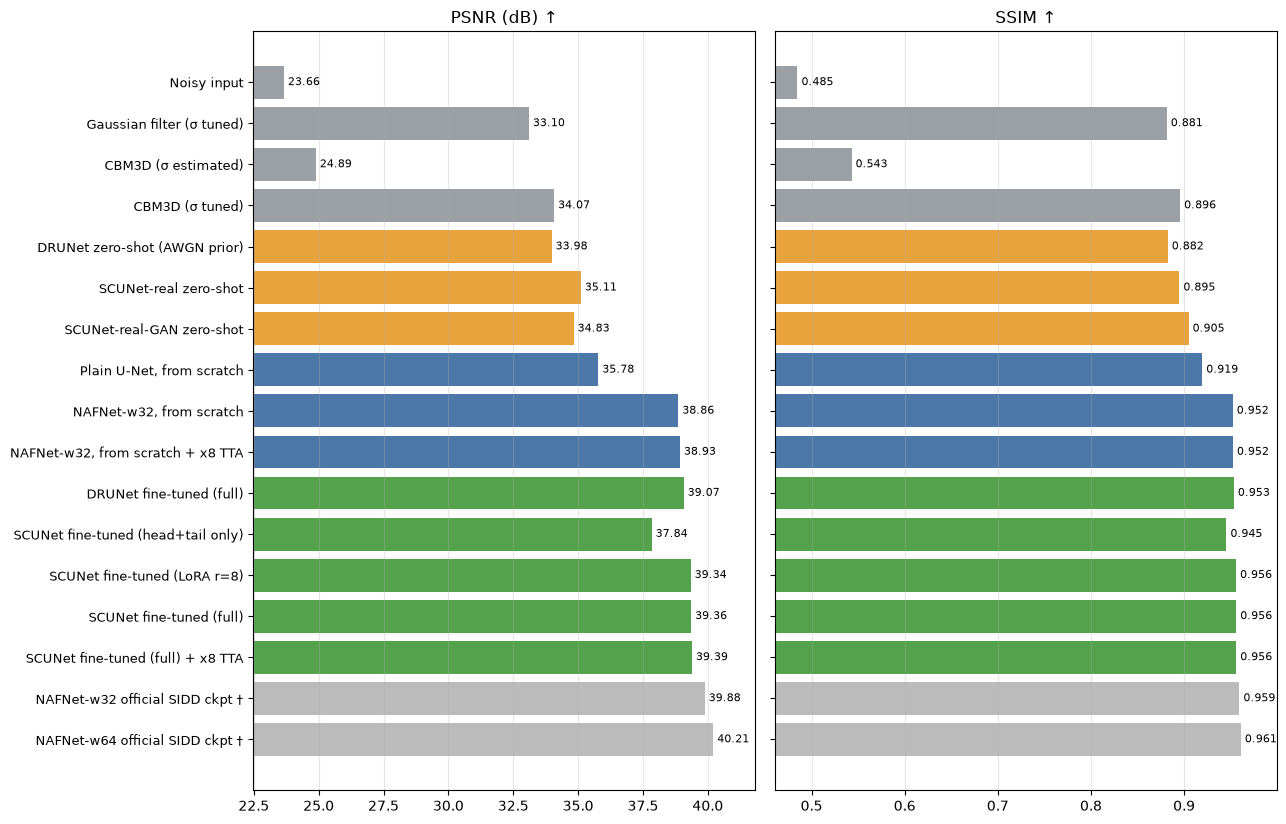

In [2]:
Path("results/figures").mkdir(parents=True, exist_ok=True)
_ = report.plot_bars(rows, "results/figures/bars.png")

## 2. Is the improvement real? Paired bootstrap over the 40 test images
`mean_diff` is the mean per-image PSNR difference (a − b), `p_value` is the one-sided p for a ≤ b, and `wins` counts the images where a beats b.

In [3]:
import pandas as pd
pairs = [("nafnet_w32_scratch", "bm3d_tuned"), ("scunet_ft_full", "bm3d_tuned"), ("nafnet_w32_scratch", "gaussian"),
         ("scunet_ft_full", "scunet_real_psnr_zeroshot"), ("scunet_ft_full", "nafnet_w32_scratch"),
         ("scunet_ft_lora", "scunet_ft_headtail"), ("scunet_ft_full", "scunet_ft_lora"),
         ("nafnet_w32_scratch", "unet_scratch"), ("scunet_ft_full", "drunet_ft_full"),
         ("nafnet_w32_scratch_tta", "nafnet_w32_scratch"), ("scunet_ft_full_tta", "scunet_ft_full")]
sig = pd.DataFrame(report.significance(res, pairs))
sig.round(4) if len(sig) else "no pairs available yet"

,a,b,mean_diff,ci95,p_value,wins,n
0,nafnet_w32_scratch,bm3d_tuned,4.7889,"(4.233745011288974, 5.3479537170852325)",0.0000,40,40
1,scunet_ft_full,bm3d_tuned,5.2826,"(4.718686913972073, 5.846039887287289)",0.0000,40,40
2,nafnet_w32_scratch,gaussian,5.7588,"(5.31646623876929, 6.207034334151175)",0.0000,40,40
3,scunet_ft_full,scunet_real_psnr_zeroshot,4.2495,"(3.45400299853334, 5.085590979904636)",0.0000,40,40
4,scunet_ft_full,nafnet_w32_scratch,0.4937,"(0.41851830257054723, 0.5683798249814803)",0.0000,39,40
5,scunet_ft_lora,scunet_ft_headtail,1.5043,"(1.2673944889555633, 1.7806944311327568)",0.0000,40,40
6,scunet_ft_full,scunet_ft_lora,0.0168,"(-0.004467384991798229, 0.037694567297031446)",0.0598,25,40
7,nafnet_w32_scratch,unet_scratch,3.0841,"(2.74160835689994, 3.442990484818253)",0.0000,40,40
8,scunet_ft_full,drunet_ft_full,0.2855,"(0.22912335879496318, 0.346306497875808)",0.0000,39,40
9,nafnet_w32_scratch_tta,nafnet_w32_scratch,0.0632,"(0.04044218671361221, 0.08669711628056466)",0.0000,35,40


## 3. Transfer learning: data efficiency at equal compute

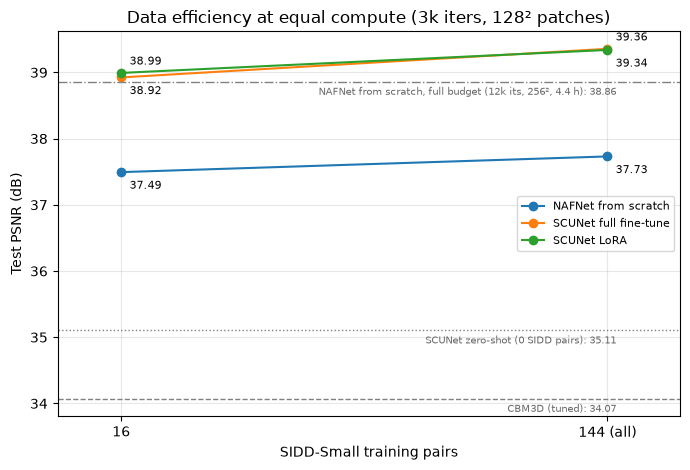

In [4]:
_ = report.plot_data_efficiency(res, "results/figures/data_efficiency.png")

## 4. Perception vs distortion

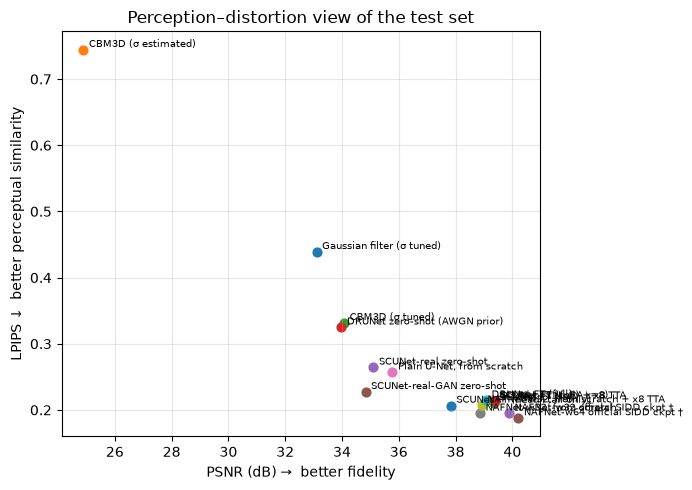

In [5]:
_ = report.plot_perception_distortion(rows, "results/figures/perception_distortion.png")

## 5. Training curves

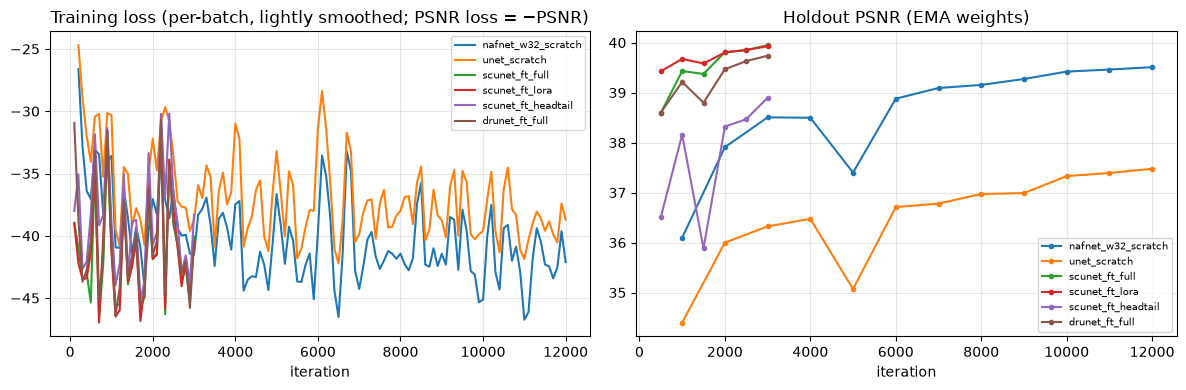

In [6]:
_ = report.plot_training_curves(["nafnet_w32_scratch", "unet_scratch", "scunet_ft_full", "scunet_ft_lora",
                                  "scunet_ft_headtail", "drunet_ft_full"], path="results/figures/curves.png")

## 6. Visual comparison (96×96 zoomed centre crops of test blocks; per-crop PSNR under each tile)

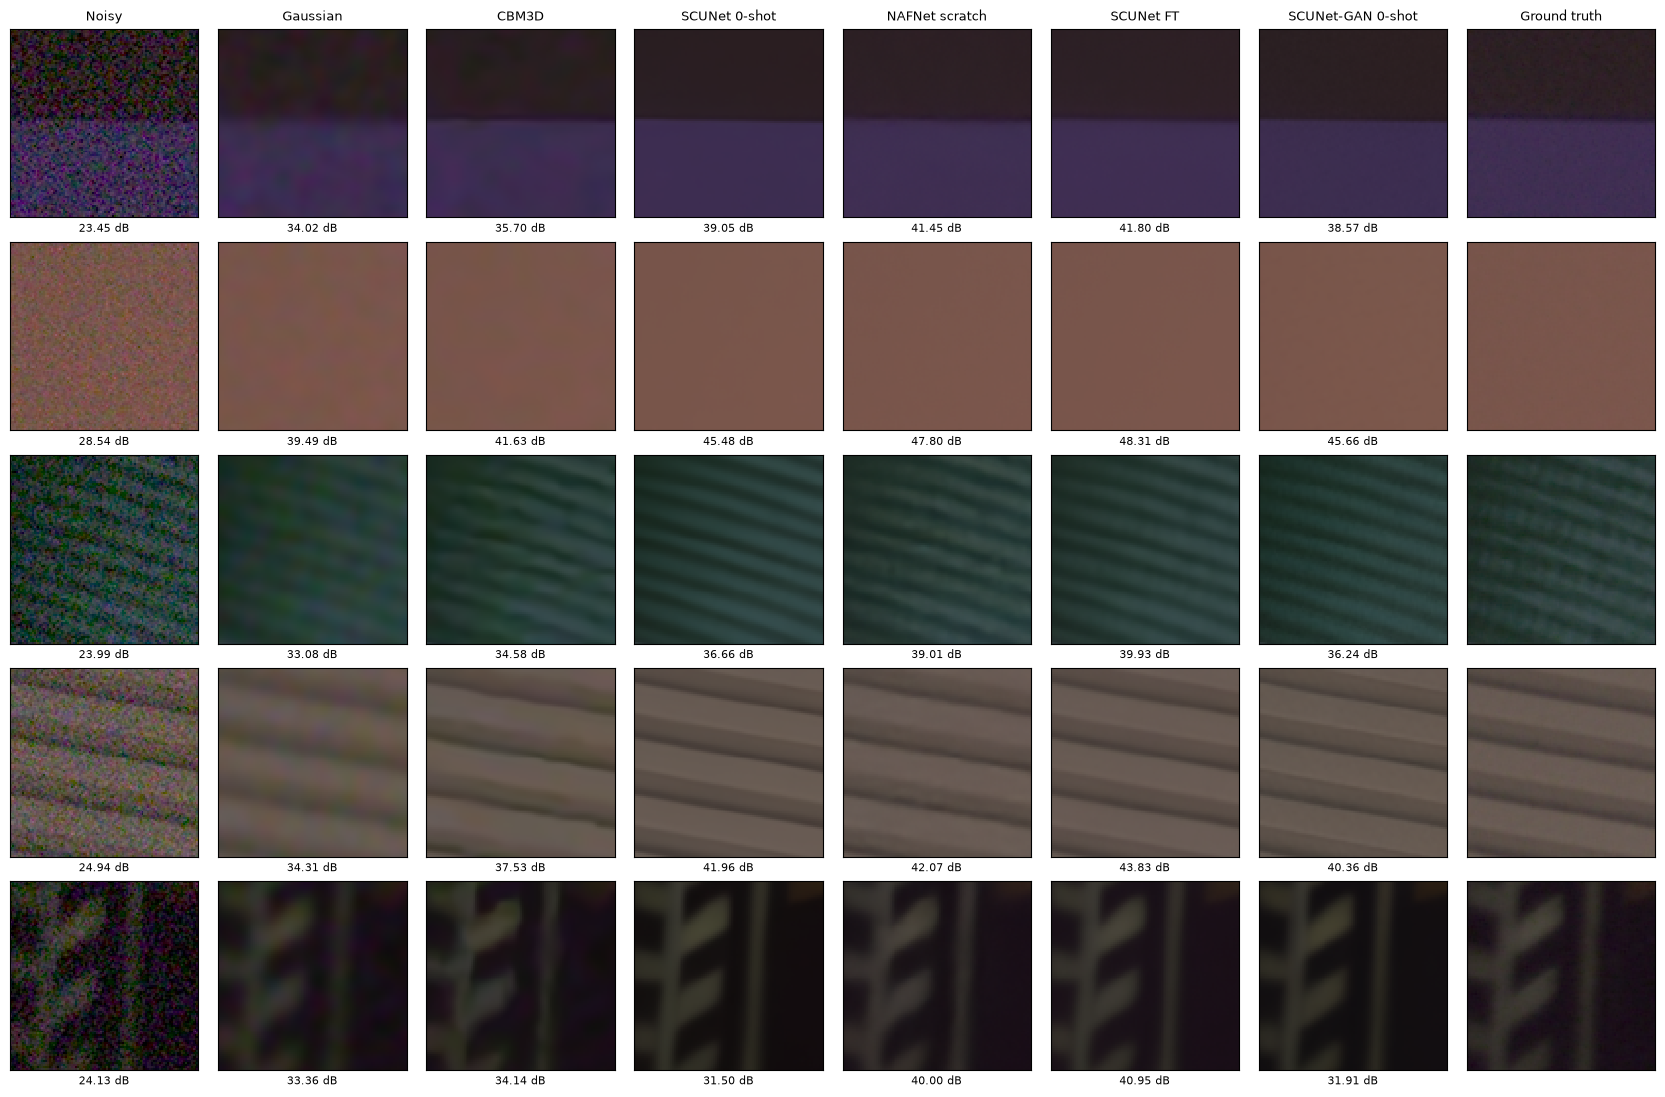

In [7]:
methods = [("Gaussian", "gaussian"), ("CBM3D", "bm3d_tuned"), ("SCUNet 0-shot", "scunet_real_psnr_zeroshot"),
           ("NAFNet scratch", "nafnet_w32_scratch"), ("SCUNet FT", "scunet_ft_full"), ("SCUNet-GAN 0-shot", "scunet_real_gan_zeroshot")]
methods = [m for m in methods if m[1] in res]
_ = report.plot_visual_grid(methods, path="results/figures/visual_grid.png")

## 7. Where do the gains come from?

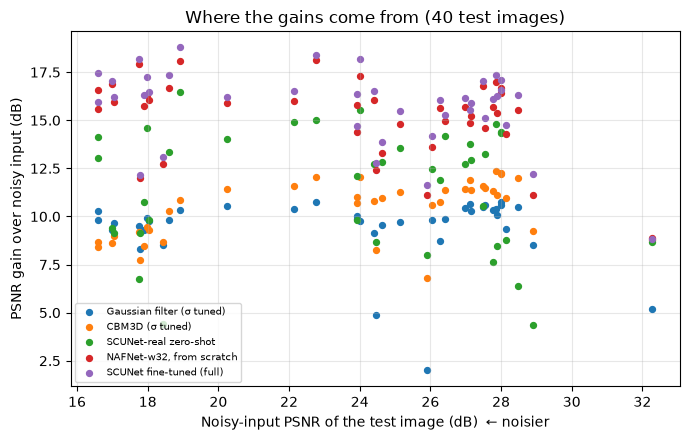

In [8]:
_ = report.plot_gain_vs_noise(res, ["gaussian", "bm3d_tuned", "scunet_real_psnr_zeroshot", "nafnet_w32_scratch", "scunet_ft_full"],
                              path="results/figures/gain_vs_noise.png")

## 8. Baseline tuning (holdout split of SIDD-Small, never the test set)

In [9]:
for f in ["results/baseline_tuning.json", "results/drunet_sigma_tuning.json"]:
    if Path(f).exists():
        print(f, json.dumps(json.loads(Path(f).read_text()), indent=1)[:800])

results/baseline_tuning.json {
 "gaussian": {
  "best_sigma": 3.0,
  "holdout_psnr": {
   "0.5": 28.577466705199566,
   "1.0": 31.79421454782592,
   "1.5": 33.58990867162855,
   "2.0": 34.65403830342784,
   "2.5": 35.154756237708305,
   "3.0": 35.2995674879576,
   "4.0": 35.03573083175047,
   "5.0": 34.49159782079447,
   "6.0": 33.910366295596326
  }
 },
 "bm3d": {
  "best_sigma": 50,
  "holdout_psnr": {
   "10": 31.1724600908699,
   "20": 35.11150916873473,
   "30": 36.34092399168094,
   "40": 36.79790236035464,
   "50": 36.852782566665255,
   "65": 36.696888020939845,
   "80": 36.4932502582699,
   "100": 36.20201724349156
  }
 }
}
results/drunet_sigma_tuning.json {
 "best_sigma": 50,
 "holdout_psnr": {
  "10": 30.463117961706594,
  "20": 35.03980407886943,
  "30": 36.2592733090326,
  "40": 36.62443578156921,
  "50": 36.64471246609414,
  "65": 36.04395529827745,
  "80": 35.41794948299946,
  "100": 34.702653074536514
 }
}
